In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision import transforms
from torchvision.transforms import functional as TF
from PIL import Image
import torch
from collections import Counter
import numpy as np
from torch.amp import GradScaler, autocast
from tqdm import tqdm

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

### Data Loader

In [3]:
ds = load_dataset("Ar4ikov/celebA_spoof")

Resolving data files:   0%|          | 0/93 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/65 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/93 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/65 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/78 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/56 [00:00<?, ?it/s]

In [86]:
len(ds['train'])

419935

In [87]:
len(ds['test'])

59191

In [4]:
img_size = 224
random_erase_prob = 0.25  
batch_size = 32
persistent_workers = True
prefetch_factor = 4
num_workers = 4
pin_memory = True
min_lr = 1e-6
warmup_epochs = 3

In [22]:
def get_transforms(is_train=True):
    if is_train:
        return transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.RandomCrop(img_size),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
            transforms.RandomRotation(15),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            transforms.RandomErasing(p=random_erase_prob),
        ])
    else:
        return transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

def letterbox(img, size):
    img = img if isinstance(img, Image.Image) else Image.open(img).convert("RGB")
    img.thumbnail((size, size), Image.Resampling.LANCZOS)

    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    x = (size - img.width) // 2
    y = (size - img.height) // 2
    canvas.paste(img, (x, y))

    return canvas

class CelebASpoofDataset(Dataset):
    def __init__(self, data, is_train=True):
        self.data = data
        self.transform = get_transforms(is_train)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img = self.data[idx]['Filepath']
        label = 1 if self.data[idx]['Class'] == 'live' else 0

        img = letterbox(img, img_size)
        arr_img = self.transform(img)

        return img, arr_img, label, idx

In [23]:
def dataset_collate(batch):
    images  = []
    targets = []
    indicies = []
    for _, arr_img, label, idx in batch:
        images.append(arr_img)
        targets.append(label)
        indicies.append(idx)
    images  = torch.from_numpy(np.array(images)).type(torch.FloatTensor)
    targets = torch.from_numpy(np.array(targets)).long()
    indicies = torch.from_numpy(np.array(indicies)).long()
    return images, targets, indicies

In [29]:
ds_test = ds['test'].shuffle(seed=42).select(range(10_000))
test_dataset = CelebASpoofDataset(ds_test, is_train=False)

In [30]:
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size * 2,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    persistent_workers=persistent_workers,
    prefetch_factor=prefetch_factor,
    collate_fn=dataset_collate,
)

### Model

In [9]:
model_name = "vit_base_patch16_224"
pretrained = True
dropout = 0.1
num_classes = 2

In [10]:
class ViTFaceAntiSpoofing(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        embed_dim = self.vit.num_features if hasattr(self.vit, 'num_features') else 768
        
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(dropout),
            nn.Linear(embed_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        features = self.vit(x)
        return self.classifier(features)

In [11]:
model = ViTFaceAntiSpoofing().to(device)

In [12]:
sum(p.numel() for p in model.parameters())

86194946

### Load Model

In [13]:
checkpoint = torch.load("model_final.pth", map_location=device, weights_only=True)

In [14]:
model = ViTFaceAntiSpoofing().to(device)
model.load_state_dict(checkpoint)

<All keys matched successfully>

### Test

In [15]:
model.eval()
pass

In [31]:
len(test_dataset)

10000

In [17]:
mixed_precision = True

In [32]:
with torch.no_grad():
    all_preds = []
    all_labels = []
    all_probs = []
    all_indices = []
    
    pbar = tqdm(test_loader, desc="Testing")
    
    for images, labels, indices in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        with autocast(device_type=device.type, enabled=mixed_precision):
            outputs = model(images)
        
        probs = F.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())  # Probability of being live
        all_indices.extend(indices.numpy())

Testing: 100%|████████████████████████████████████████████████████████████████| 157/157 [18:26<00:00,  7.05s/it]


In [33]:
y_pred, y_true, y_prob, indices = np.array(all_preds), np.array(all_labels), np.array(all_probs), np.array(all_indices)

In [34]:
np.savez(
    "predictions.npz",
    y_pred=y_pred,
    y_true=y_true,
    y_prob=y_prob,
    indices=indices
)

### Metrics

In [62]:
from scripts.metric import calculate_metrics, print_metrics, save_results
import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.cuda.amp import autocast
import timm
from PIL import Image
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import logging
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support, 
    roc_auc_score, 
    confusion_matrix,
    classification_report,
    roc_curve
)
import warnings
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [54]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

In [37]:
metrics, cm = calculate_metrics(y_true, y_pred, y_prob)

2026-10-19 14:28:18,607 - INFO - 
2026-10-19 14:28:18,610 - INFO - CALCULATING METRICS
2026-10-19 14:28:18,611 - INFO - ============================================================


In [38]:
metrics

{'accuracy': 0.6073,
 'precision': 0.39937161808343513,
 'recall': 0.8248017303532804,
 'f1_score': 0.538163001293661,
 'auc': 0.7513190870666309,
 'specificity': np.float64(0.5238029338499861),
 'npv': np.float64(0.8862093186607352),
 'ppv': np.float64(0.39937161808343513),
 'far': np.float64(0.47619706615001384),
 'frr': np.float64(0.17519826964671953),
 'eer': np.float64(0.32193282448963134),
 'tp': 2288,
 'tn': 3785,
 'fp': 3441,
 'fn': 486,
 'total_samples': 10000,
 'live_samples': 2774,
 'spoof_samples': 7226}

In [42]:
print_metrics(metrics)

2026-10-19 14:29:11,417 - INFO - 
2026-10-19 14:29:11,419 - INFO - TEST RESULTS
2026-10-19 14:29:11,420 - INFO - ============================================================
2026-10-19 14:29:11,421 - INFO - 
Overall Performance:
2026-10-19 14:29:11,423 - INFO -   Accuracy:        0.6073 (60.73%)
2026-10-19 14:29:11,424 - INFO -   AUC-ROC:         0.7513
2026-10-19 14:29:11,425 - INFO -   F1-Score:        0.5382
2026-10-19 14:29:11,427 - INFO - 
Detection Metrics (Live Class):
2026-10-19 14:29:11,428 - INFO -   Precision (PPV): 0.3994
2026-10-19 14:29:11,429 - INFO -   Recall (TPR):    0.8248
2026-10-19 14:29:11,429 - INFO -   Specificity:     0.5238
2026-10-19 14:29:11,431 - INFO -   NPV:             0.8862
2026-10-19 14:29:11,432 - INFO - 
Error Rates:
2026-10-19 14:29:11,433 - INFO -   FAR (FPR):       0.4762 (47.62%)
2026-10-19 14:29:11,434 - INFO -   FRR (FNR):       0.1752 (17.52%)
2026-10-19 14:29:11,435 - INFO -   EER:             0.3219 (32.19%)
2026-10-19 14:29:11,436 - INFO -

In [43]:
output_dir = "./test_results"

In [49]:
cm_df = pd.DataFrame(
    cm,
    columns=['Predicted Spoof', 'Predicted Live'],
    index=['Actual Spoof', 'Actual Live']
)

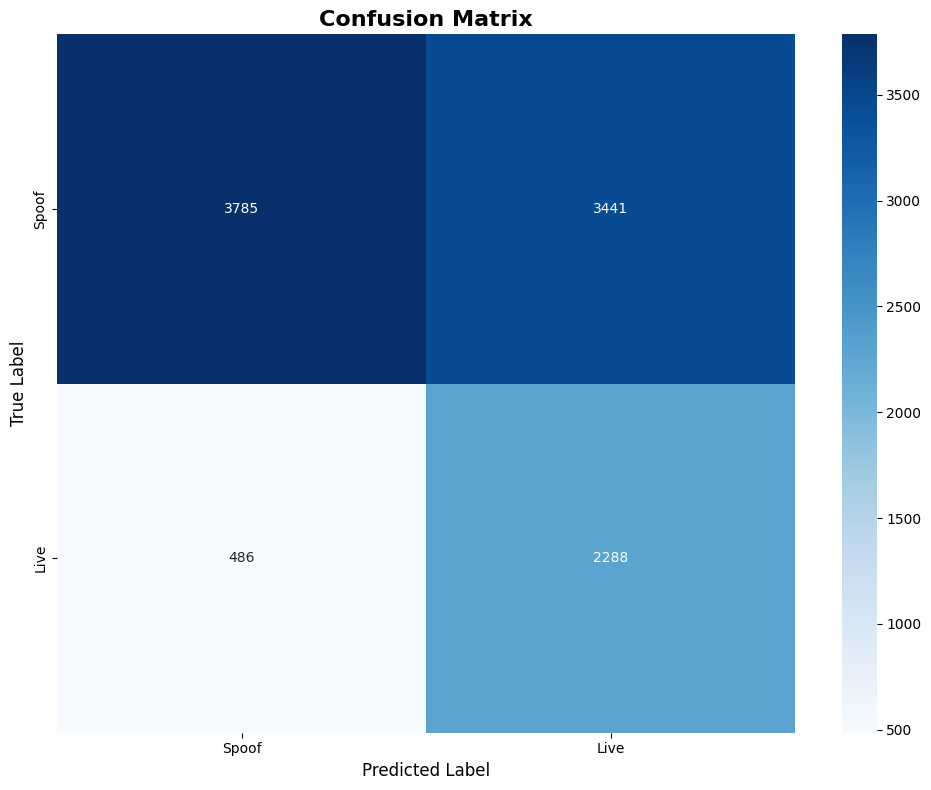

In [57]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Spoof', 'Live'],
            yticklabels=['Spoof', 'Live'])
plt.title('Confusion Matrix', fontsize=16, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plot_path = output_dir + "/" + f"confusion_matrix_{timestamp}.png"
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
plt.show()

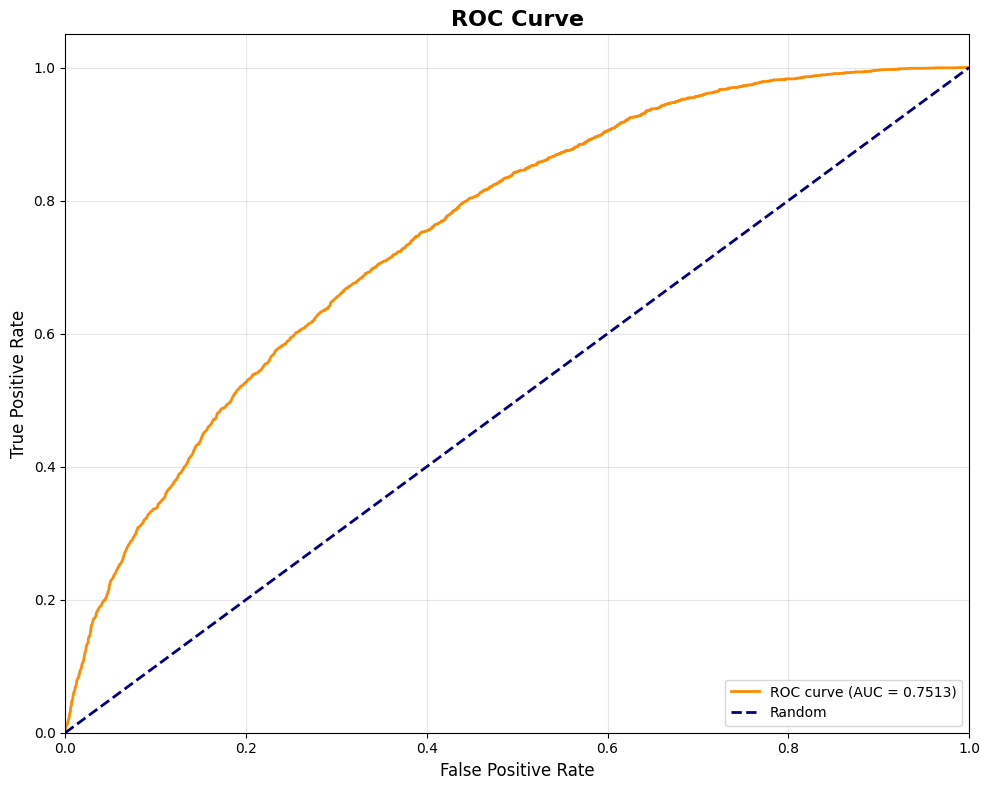

In [59]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve', fontsize=16, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
roc_path = output_dir +  "/" + f"roc_curve_{timestamp}.png"
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()

### Example Results

In [83]:
def show_predictions(y_pred, y_true, y_prob, indices, test_dataset, indexes=None, n=10):
    if indexes is not None:
        selected = [i for i, idx in enumerate(indices) if int(idx) in indexes]
    else:
        n = min(n, len(indices))
        selected = random.sample(range(len(indices)), n)

    n = len(selected)
    if n == 0:
        print("No matching indexes found.")
        return

    cols = min(5, n)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    label_map = {1: "Live", 0: "Spoof"}

    for ax, i in zip(axes, selected):
        idx = int(indices[i])

        img, _, label, _ = test_dataset[idx]
        img = np.asarray(img)

        ax.imshow(img)
        ax.set_title(
            f"Index: {idx}\n"
            f"Label: {label_map[int(y_true[i])]} | "
            f"Pred: {label_map[int(y_pred[i])]}\n"
            f"Prob (Live): {np.asarray(y_prob[i]).round(4)}",
            fontsize=10
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.5)

    save_path = "test_results/example.png"
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    print(f"Plot saved to {save_path}")

    plt.show()
    plt.close(fig)

In [84]:
indexes = [4478, 4989, 6856, 3003, 7227, 5981, 1886, 2726, 6134, 8288, 6872, 3407, 9787, 4498, 7162]

Plot saved to test_results/example.png


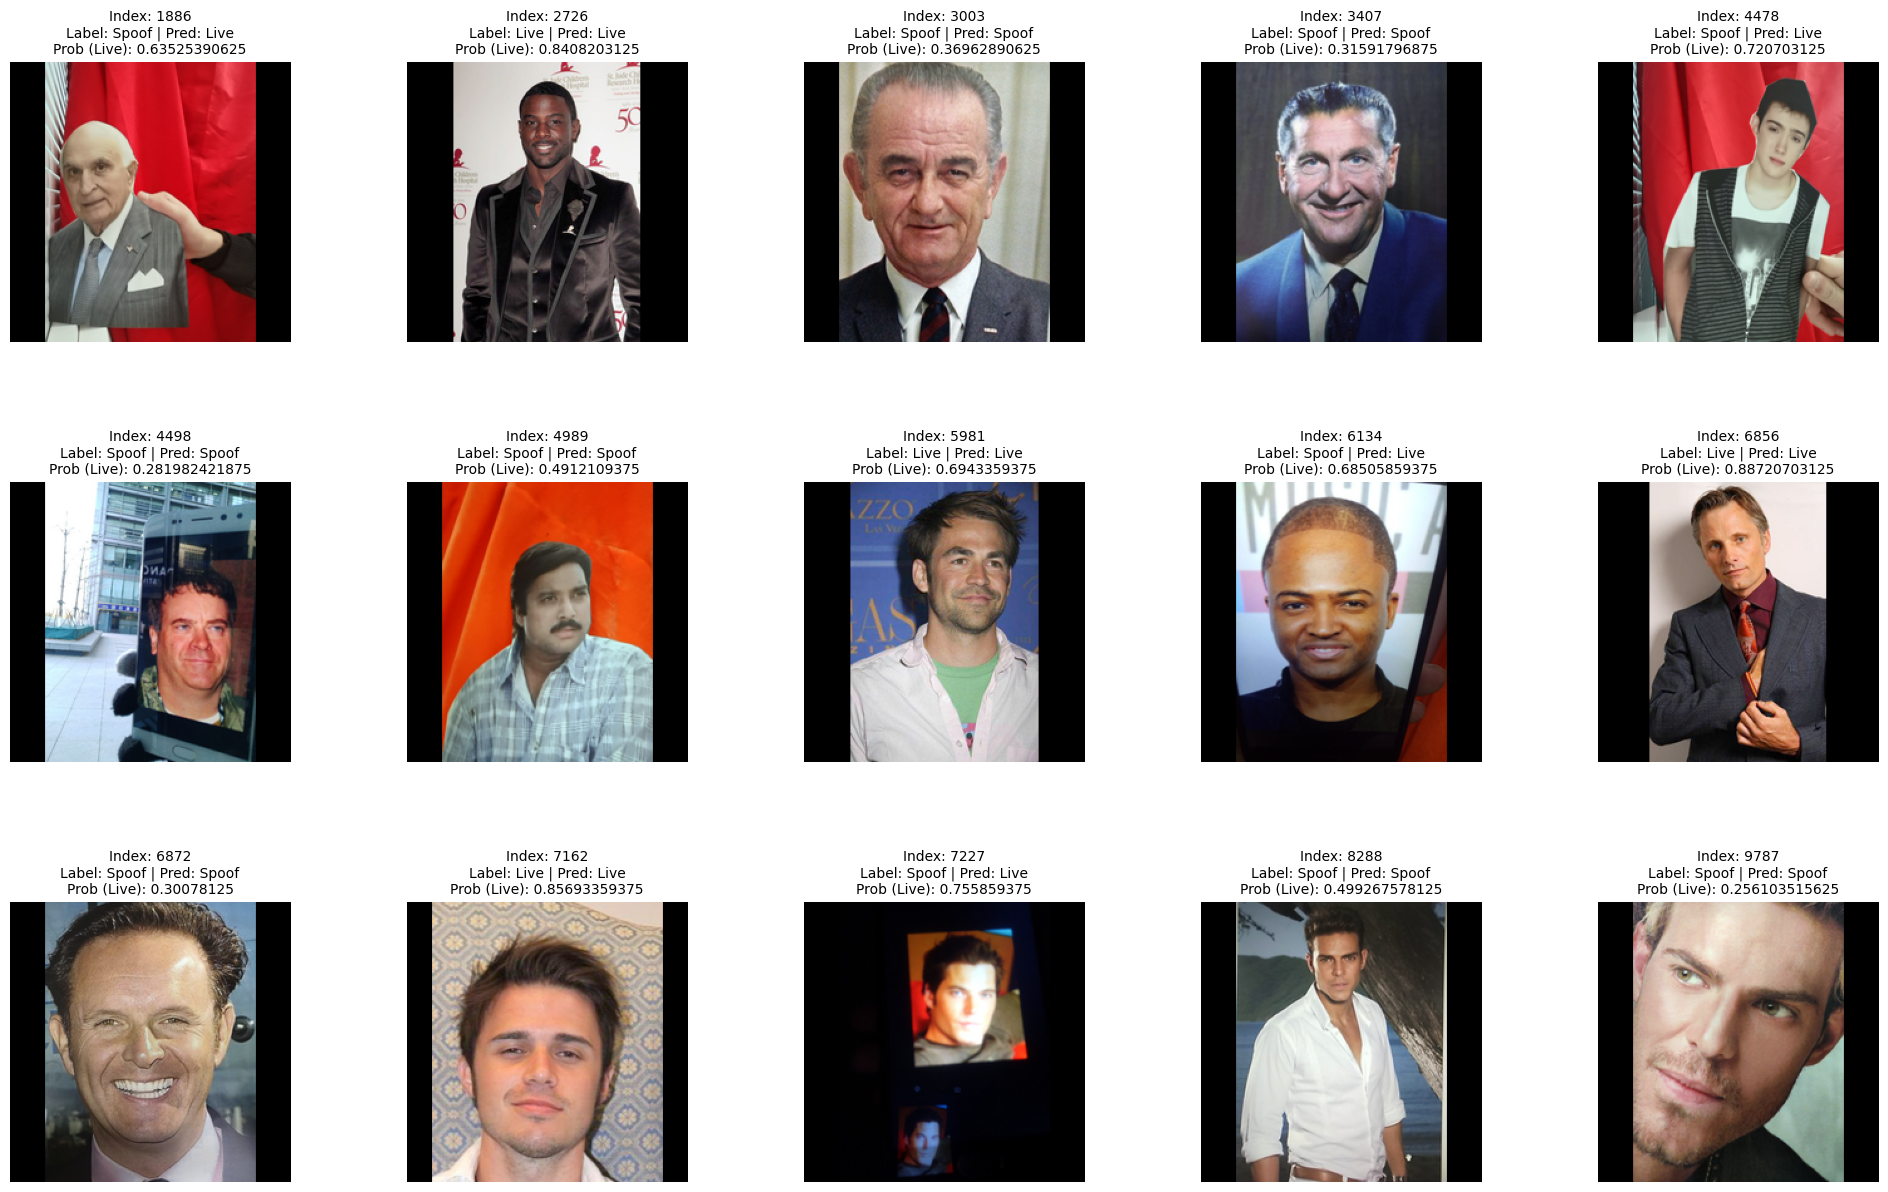

In [85]:
show_predictions(
    y_pred=y_pred,
    y_true=y_true,
    y_prob=y_prob,
    indices=indices,
    test_dataset=test_dataset,
    indexes=indexes
)

In [88]:
!ls test_results/

confusion_matrix.png  roc_curve.png
example.png	      test_metrics_20261019_142945.csv
